# Análisis Clínico Bivariado
## Asociación de manifestaciones clínicas con la hospitalización por dengue

**Cohorte:** DCSA n=12,713 (64.8% hospitalización) · DSSA n=15,734 (3.9%)

---

El análisis bivariado cuantifica la fuerza de asociación entre cada
manifestación clínica y el desenlace de hospitalización mediante Odds Ratios
crudos. Su limitación es la colinealidad: síntomas que tienden a co-ocurrir
(dolor abdominal + vómito, por ejemplo) no pueden evaluarse de forma
independiente en este nivel de análisis. La asociación ajustada se estima
en el notebook 02b con regresión logística multivariada.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
import joblib
from pathlib import Path

warnings.filterwarnings('ignore')
%matplotlib inline

plt.rcParams.update({
    'figure.dpi': 150, 'savefig.dpi': 300,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 14, 'axes.titleweight': 'bold',
    'axes.labelsize': 12, 'xtick.labelsize': 10,
    'ytick.labelsize': 10, 'legend.frameon': False,
})

COLORS = {
    'primary': '#2C7BB6', 'secondary': '#D7191C',
    'accent': '#FDAE61', 'neutral': '#7F7F7F',
    'con_signos': '#E74C3C', 'sin_signos': '#3498DB', 'grave': '#8E44AD',
}
SIGNOS_ALARMA = [
    'DOLOR_ABDO','VOMITO','DIARREA','SOMNOLENCI',
    'HIPOTENSIO','HEPATOMEG','HEM_MUCOSA',
    'HIPOTERMIA','AUM_HEMATO','CAIDA_PLAQ','ACUM_LIQUI'
]
SINTOMAS_GENERALES = ['FIEBRE','CEFALEA','DOLRRETROO','MALGIAS','ARTRALGIA','ERUPCIONR']
TARGET = 'TARGET_HOSPITALIZACION_ORIGINAL'

NB_DIR = Path('.')
ROOT   = Path(r'D:\Documentos\GitHub\dengue')  # <-- edita aqui
OUT_FIG     = ROOT / 'outputs' / 'figures'
OUT_TAB     = ROOT / 'outputs' / 'tables'
INTERIM     = ROOT / 'data' / 'interim'
CHECKPOINTS = ROOT / 'outputs' / 'checkpoints'
for p in [OUT_FIG, OUT_TAB, INTERIM, CHECKPOINTS]:
    p.mkdir(parents=True, exist_ok=True)
print('Entorno listo')

Entorno listo


In [2]:
# Cargar datos estratificados desde el checkpoint del EDA
df_con = joblib.load(INTERIM / 'datos_con_signos.pkl')
df_sin = joblib.load(INTERIM / 'datos_sin_signos.pkl')
print(f'DCSA : {len(df_con):,} casos · {df_con[TARGET].mean():.1%} hospitalizados')
print(f'DSSA : {len(df_sin):,} casos · {df_sin[TARGET].mean():.1%} hospitalizados')

DCSA : 12,713 casos · 64.8% hospitalizados
DSSA : 15,734 casos · 3.9% hospitalizados


## 1. Odds Ratios crudos — función de análisis

Se calcula OR crudo con IC95% (método de Woolf) y p-valor.
La corrección de Benjamini-Hochberg controla la tasa de falsos positivos
al realizar 17 pruebas simultáneas sobre el mismo outcome.

In [3]:
from scipy.stats import chi2_contingency, fisher_exact
from statsmodels.stats.multitest import multipletests

def odds_ratios(df, variables, target):
    """
    Calcula OR crudo con IC95% y p-valor para variables binarias (1/2) vs target (0/1).
    Aplica corrección Benjamini-Hochberg (FDR) para comparaciones múltiples.
    El método de Woolf para el IC es robusto ante celdas con conteos bajos.
    """
    rows = []
    for var in variables:
        pres   = df[var].map({1: 1, 2: 0})
        tgt    = df[target]
        valido = pres.notna() & tgt.notna()
        tbl    = pd.crosstab(pres[valido], tgt[valido])
        if tbl.shape != (2, 2):
            continue
        a = max(tbl.iloc[1, 1], 0.5)
        b = max(tbl.iloc[1, 0], 0.5)
        c = max(tbl.iloc[0, 1], 0.5)
        d = max(tbl.iloc[0, 0], 0.5)
        OR  = (a * d) / (b * c)
        se  = np.sqrt(1/a + 1/b + 1/c + 1/d)
        lo  = np.exp(np.log(OR) - 1.96 * se)
        hi  = np.exp(np.log(OR) + 1.96 * se)
        _, p, _, _ = chi2_contingency(tbl.values)
        rows.append({
            'Variable': var,
            'Tipo': 'Signo de alarma' if var in SIGNOS_ALARMA else 'Sintoma general',
            'Hosp_%': round(tbl.iloc[1, 1] / tbl.iloc[:, 1].sum() * 100, 1),
            'NoHosp_%': round(tbl.iloc[1, 0] / tbl.iloc[:, 0].sum() * 100, 1),
            'OR': round(OR, 3), 'IC95_inf': round(lo, 3), 'IC95_sup': round(hi, 3),
            'p_valor': p,
        })
    res = pd.DataFrame(rows)
    _, p_adj, _, _ = multipletests(res['p_valor'], method='fdr_bh')
    res['p_adj_BH']      = p_adj.round(5)
    res['Significativo'] = res['p_adj_BH'] < 0.05
    return res.sort_values('OR', ascending=False).reset_index(drop=True)

todas = SINTOMAS_GENERALES + SIGNOS_ALARMA
tabla_con = odds_ratios(df_con, todas, TARGET)
tabla_sin = odds_ratios(df_sin, todas, TARGET)

tabla_con.to_csv(OUT_TAB / 'OR_crudos_DCSA.csv', index=False)
tabla_sin.to_csv(OUT_TAB / 'OR_crudos_DSSA.csv', index=False)

print('DCSA — top 5 por OR:')
display(tabla_con[['Variable','Tipo','Hosp_%','NoHosp_%','OR','IC95_inf','IC95_sup','Significativo']].head(5))

DCSA — top 5 por OR:


,Variable,Tipo,Hosp_%,NoHosp_%,OR,IC95_inf,IC95_sup,Significativo
0,FIEBRE,Sintoma general,78.3,34.5,6.821,6.291,7.395,True
1,CAIDA_PLAQ,Signo de alarma,46.2,13.5,5.488,4.985,6.041,True
2,MALGIAS,Sintoma general,68.5,29.1,5.297,4.892,5.736,True
3,ARTRALGIA,Sintoma general,56.0,23.1,4.235,3.902,4.597,True
4,CEFALEA,Sintoma general,63.9,29.9,4.156,3.843,4.494,True


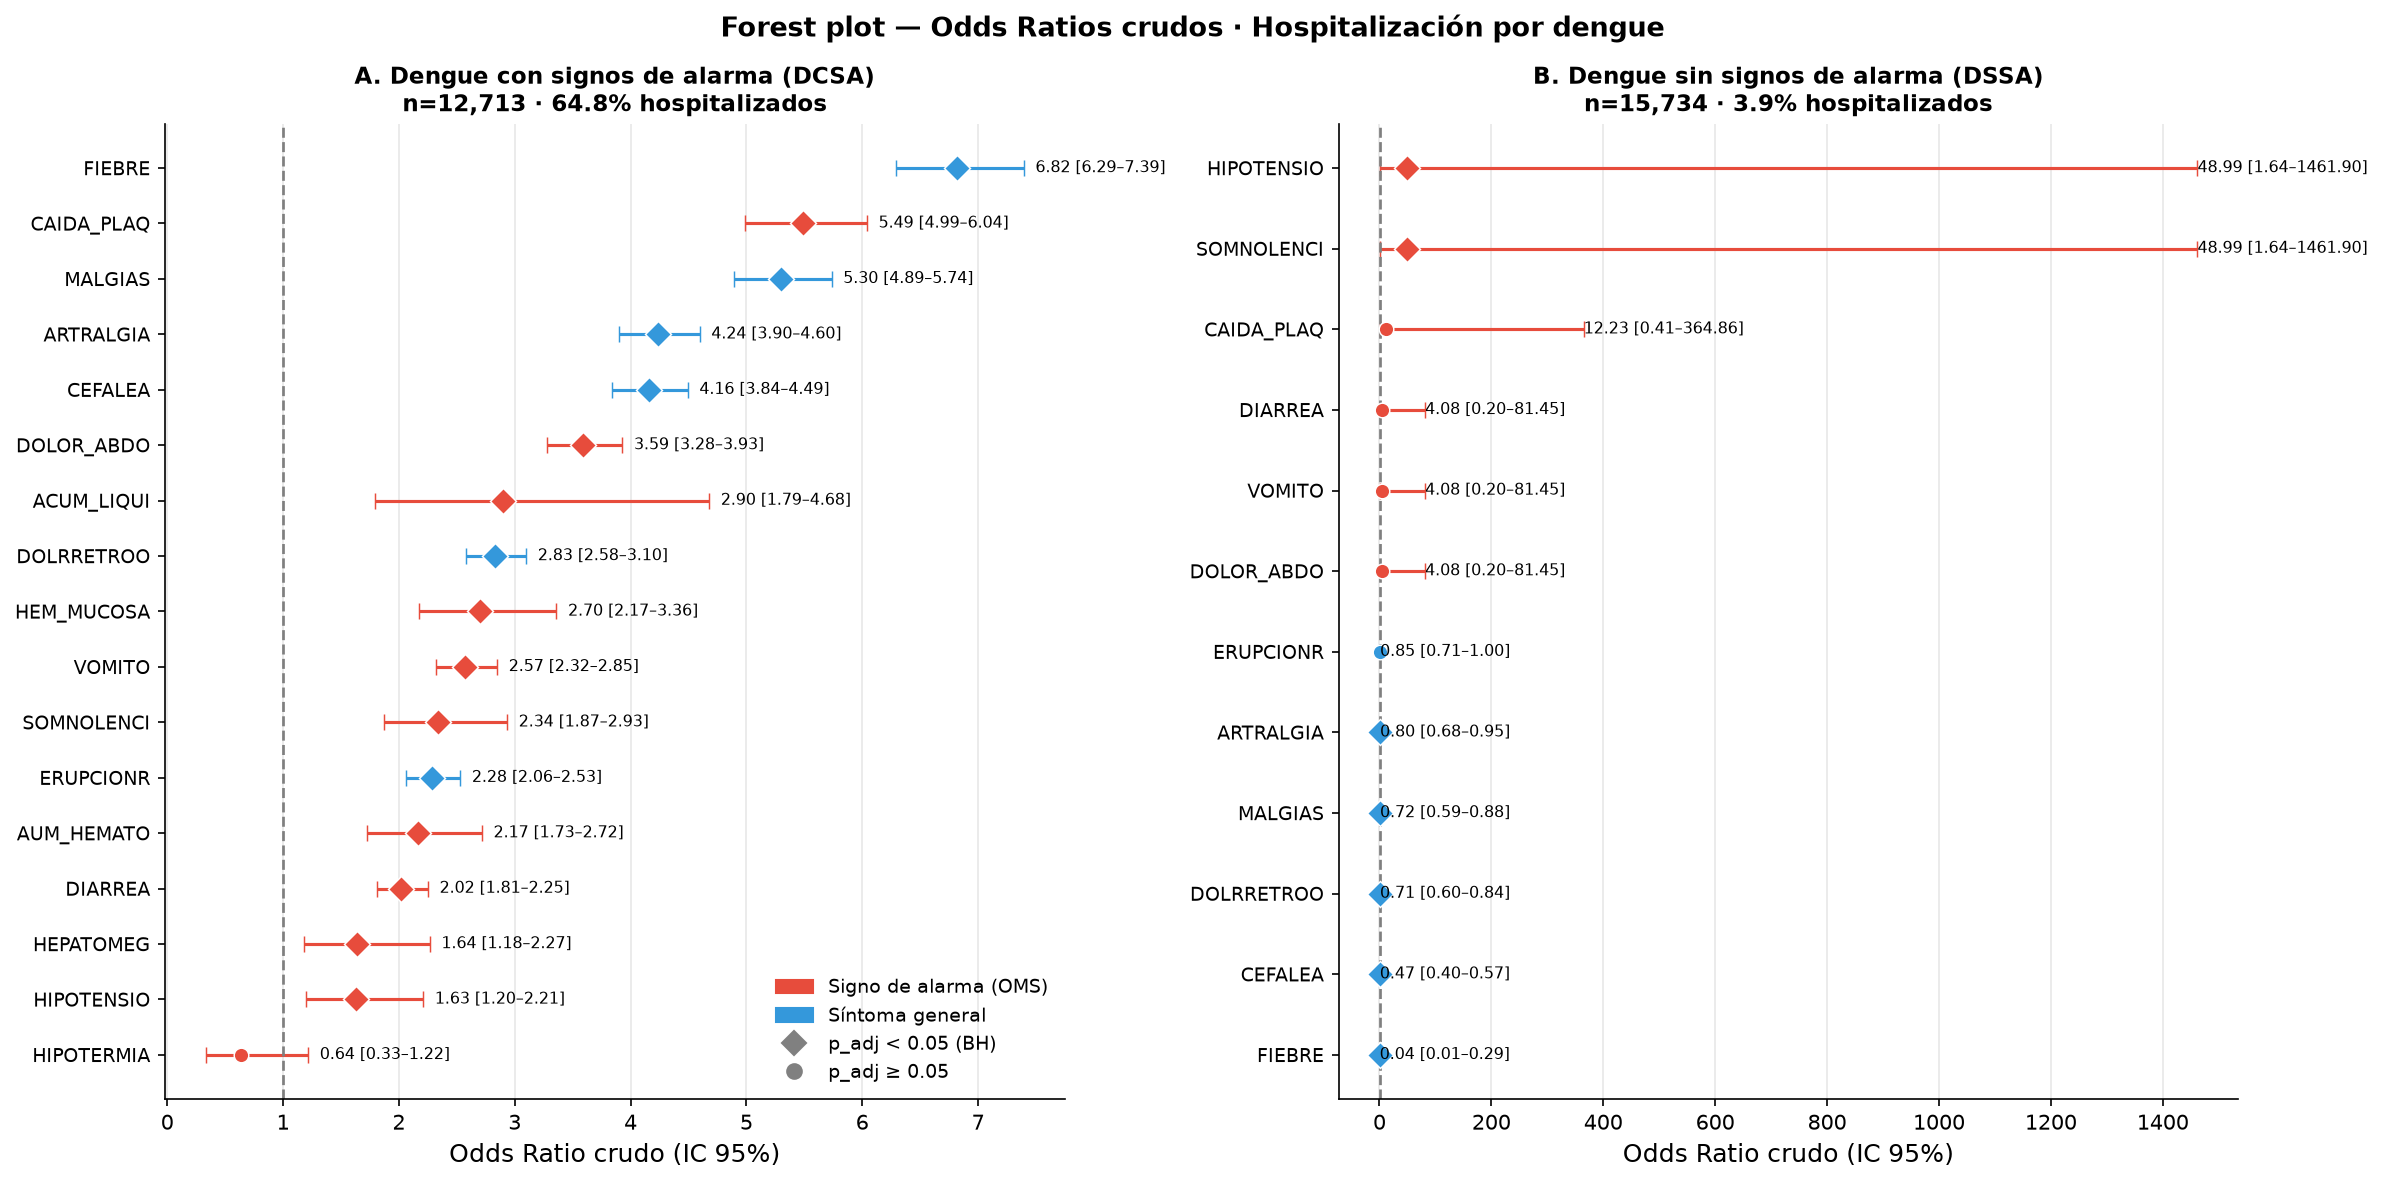

In [4]:
# Forest plot comparativo DCSA vs DSSA
# Permite identificar si un mismo signo tiene distinta capacidad discriminativa
# según el estrato clínico — diferencias marcadas justifican el modelado separado
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

for ax, tabla, titulo, color_sig in zip(
    axes,
    [tabla_con, tabla_sin],
    ['A. Dengue con signos de alarma (DCSA)\nn=12,713 · 64.8% hospitalizados',
     'B. Dengue sin signos de alarma (DSSA)\nn=15,734 · 3.9% hospitalizados'],
    [COLORS['con_signos'], COLORS['sin_signos']]
):
    df_fp = tabla.dropna(subset=['OR']).sort_values('OR')
    for i, (_, f) in enumerate(df_fp.iterrows()):
        color  = COLORS['con_signos'] if f['Tipo'] == 'Signo de alarma' else COLORS['sin_signos']
        marker = 'D' if f['Significativo'] else 'o'
        size   = 9 if f['Significativo'] else 7
        ax.errorbar(
            f['OR'], i,
            xerr=[[f['OR'] - f['IC95_inf']], [f['IC95_sup'] - f['OR']]],
            fmt=marker, capsize=4, markersize=size, color=color,
            elinewidth=1.5, markeredgecolor='white', markeredgewidth=0.7)
        ax.text(f['IC95_sup'] + 0.1, i,
            f"{f['OR']:.2f} [{f['IC95_inf']:.2f}–{f['IC95_sup']:.2f}]",
            va='center', fontsize=7.5)
    ax.set_yticks(range(len(df_fp)))
    ax.set_yticklabels(df_fp['Variable'], fontsize=9)
    ax.axvline(1, color=COLORS['neutral'], linestyle='--', linewidth=1.3)
    ax.set_xlabel('Odds Ratio crudo (IC 95%)')
    ax.set_title(titulo, fontsize=11)
    ax.grid(axis='x', alpha=0.3)

leyenda = [
    mpatches.Patch(color=COLORS['con_signos'], label='Signo de alarma (OMS)'),
    mpatches.Patch(color=COLORS['sin_signos'], label='Síntoma general'),
    plt.Line2D([0],[0], marker='D', color='gray', markersize=8,
        linewidth=0, label='p_adj < 0.05 (BH)'),
    plt.Line2D([0],[0], marker='o', color='gray', markersize=7,
        linewidth=0, label='p_adj ≥ 0.05'),
]
axes[0].legend(handles=leyenda, loc='lower right', fontsize=9)

plt.suptitle(
    'Forest plot — Odds Ratios crudos · Hospitalización por dengue',
    fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig(OUT_FIG / '06_forest_OR_crudos.png', dpi=300,
    bbox_inches='tight', facecolor='white')
plt.show()

## 2. Prevalencia de signos de alarma según hospitalización

Complementa el forest plot con una visión absoluta:
¿qué tan frecuente es cada signo en hospitalizados vs no hospitalizados?

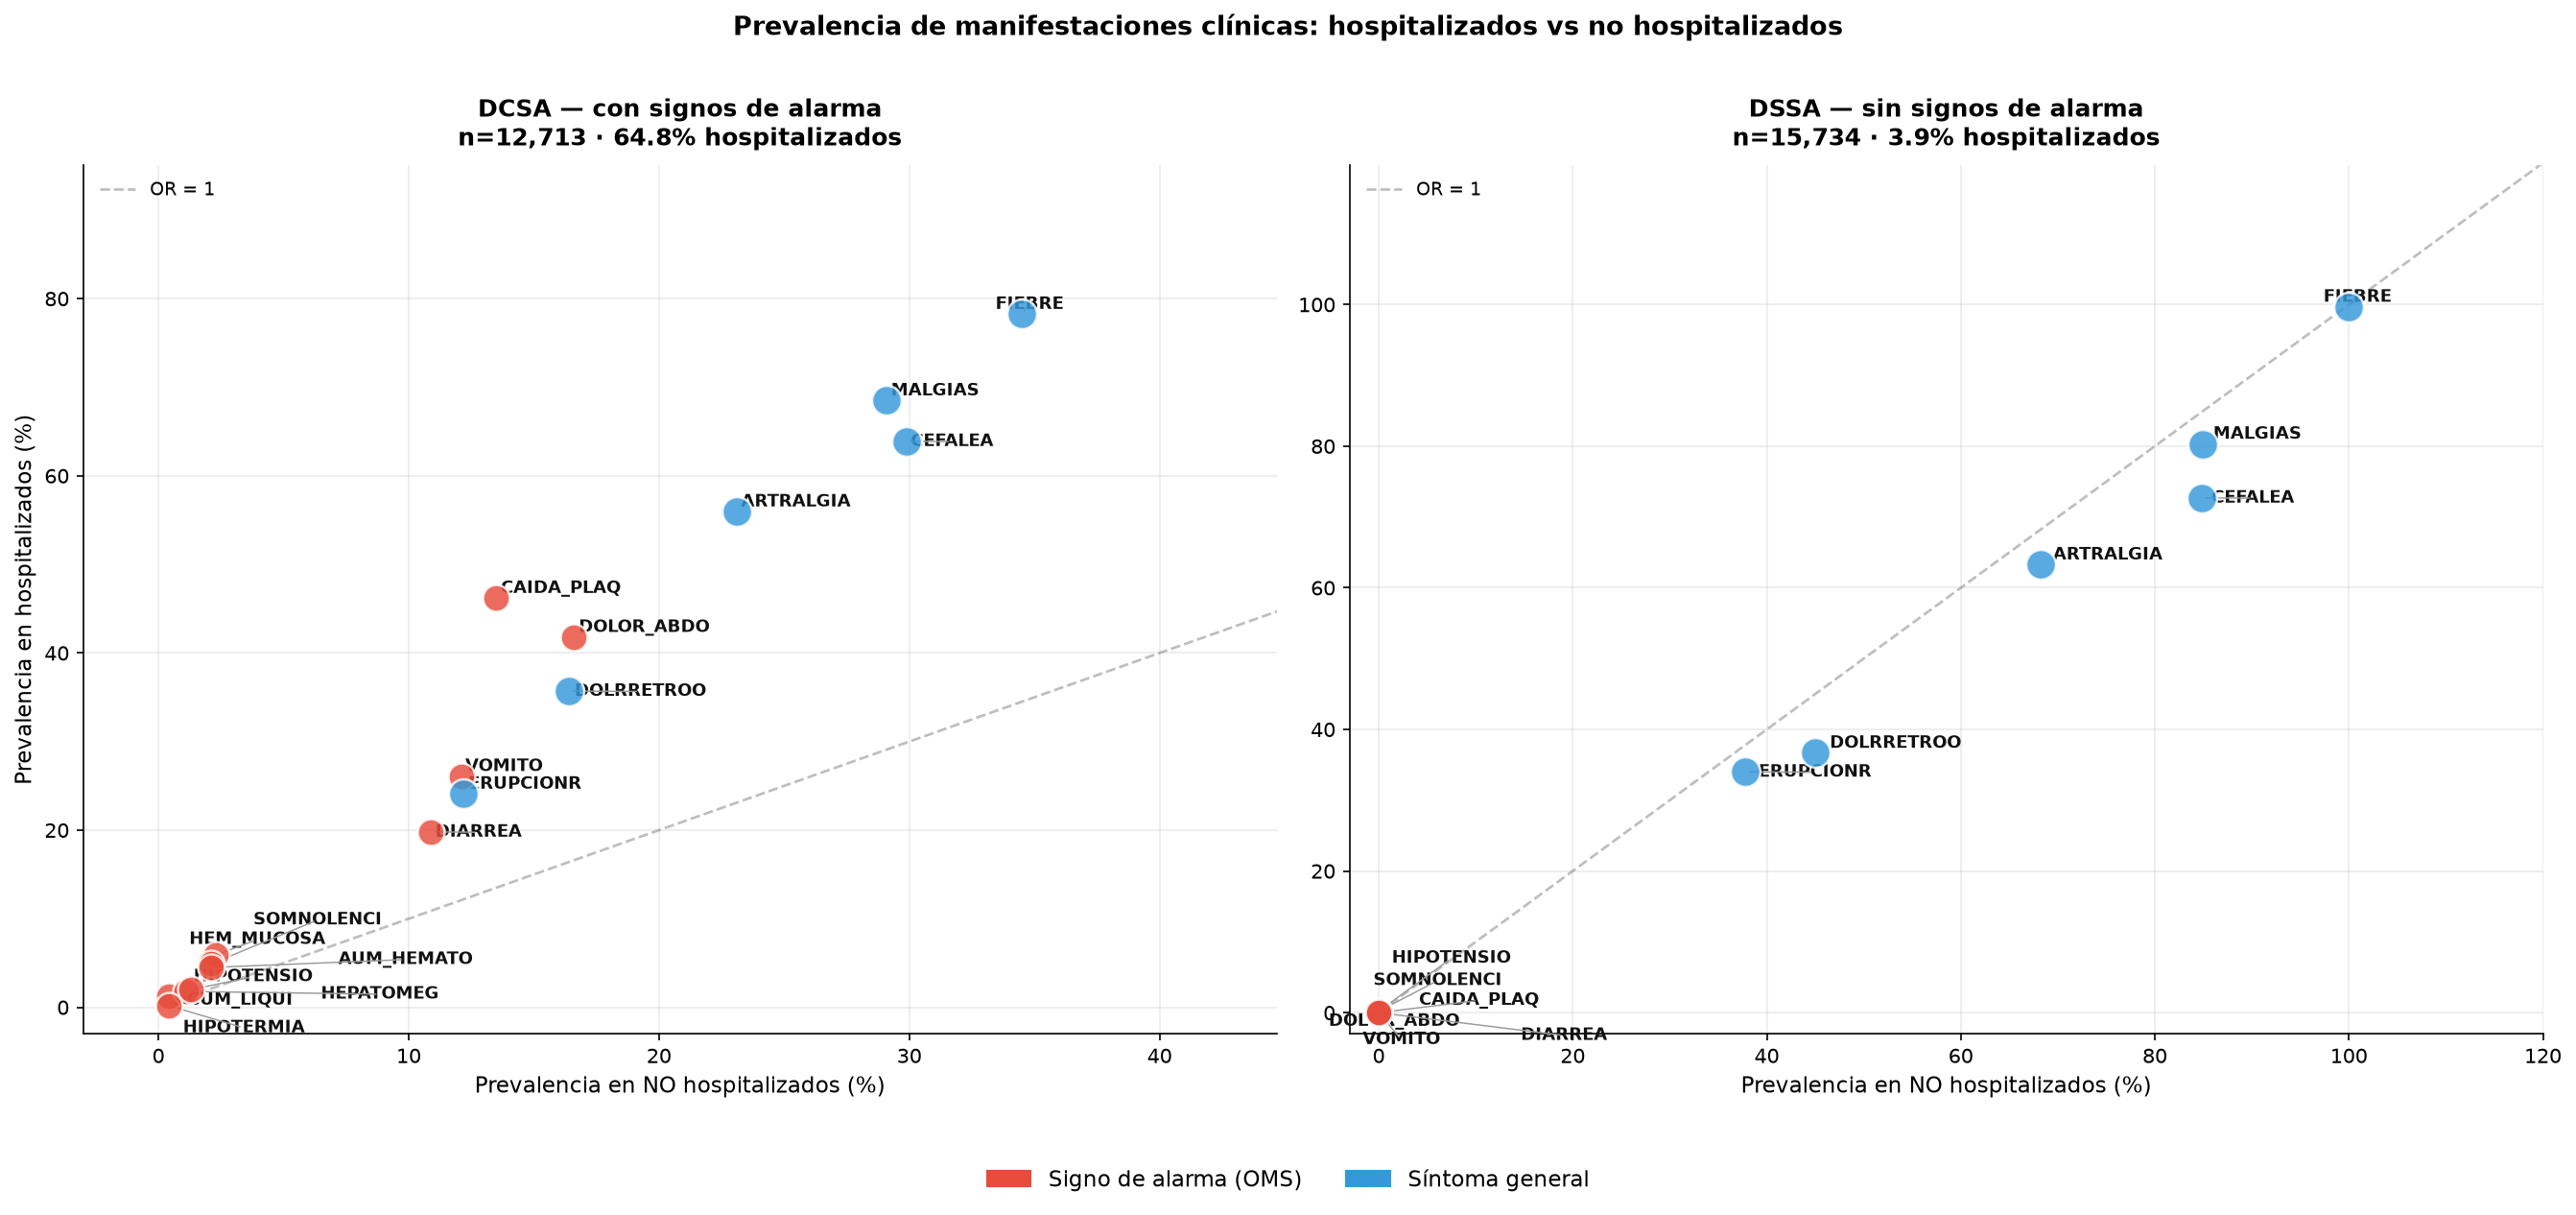

In [7]:
try:
    from adjustText import adjust_text
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'adjustText'])
    from adjustText import adjust_text

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

for ax, tabla, titulo in zip(
    axes,
    [tabla_con, tabla_sin],
    ['DCSA — con signos de alarma\nn=12,713 · 64.8% hospitalizados',
     'DSSA — sin signos de alarma\nn=15,734 · 3.9% hospitalizados']
):
    puntos_x, puntos_y, textos = [], [], []

    for _, row in tabla.iterrows():
        color = COLORS['con_signos'] if row['Tipo'] == 'Signo de alarma' else COLORS['sin_signos']
        # Tamaño fijo por tipo — evita la burbuja gigante que distorsiona DSSA
        size = 180 if row['Tipo'] == 'Signo de alarma' else 220
        ax.scatter(row['NoHosp_%'], row['Hosp_%'],
            s=size, color=color, alpha=0.82,
            edgecolors='white', linewidth=1.2, zorder=4)
        puntos_x.append(row['NoHosp_%'])
        puntos_y.append(row['Hosp_%'])
        t = ax.text(
            row['NoHosp_%'], row['Hosp_%'],
            row['Variable'],
            fontsize=8.5, color='#111111', fontweight='bold'
        )
        textos.append(t)

    # Parámetros agresivos para separar etiquetas amontonadas cerca del origen
    adjust_text(
        textos,
        x=puntos_x, y=puntos_y,
        ax=ax,
        force_text=(0.9, 1.2),
        force_points=(0.6, 0.8),
        expand_text=(1.5, 1.8),
        expand_points=(2.0, 2.2),
        lim=500,
        arrowprops=dict(arrowstyle='-', color='#999999', lw=0.7)
    )

    # Diagonal OR = 1 — escala independiente por panel
    lim_x = tabla['NoHosp_%'].max() * 1.15 + 5
    lim_y = tabla['Hosp_%'].max()   * 1.15 + 5
    lim_d = max(lim_x, lim_y)
    ax.plot([0, lim_d], [0, lim_d], '--',
        color=COLORS['neutral'], linewidth=1.3, alpha=0.5,
        label='OR = 1', zorder=2)

    ax.set_xlabel('Prevalencia en NO hospitalizados (%)', fontsize=11)
    ax.set_ylabel(
        'Prevalencia en hospitalizados (%)' if ax == axes[0] else '',
        fontsize=11)
    ax.set_title(titulo, fontsize=12, fontweight='bold', pad=10)
    ax.set_xlim(-3, lim_x)
    ax.set_ylim(-3, lim_y)
    ax.legend(fontsize=9, loc='upper left')
    ax.grid(alpha=0.25)

# Leyenda de colores al pie, centrada
leyenda_col = [
    mpatches.Patch(color=COLORS['con_signos'], label='Signo de alarma (OMS)'),
    mpatches.Patch(color=COLORS['sin_signos'], label='Síntoma general'),
]
fig.legend(handles=leyenda_col, loc='lower center', ncol=2,
    fontsize=11, bbox_to_anchor=(0.5, -0.03))

plt.suptitle(
    'Prevalencia de manifestaciones clínicas: hospitalizados vs no hospitalizados',
    fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout(rect=[0, 0.05, 1, 1])
fig.savefig(OUT_FIG / '07_burbuja_prevalencia.png', dpi=300,
    bbox_inches='tight', facecolor='white')
plt.show()

---

## Hallazgos del análisis bivariado

**DCSA:** Caída de plaquetas y dolor abdominal presentan los mayores OR crudos.
Hipotermia e hipotensión tienen OR altos pero intervalos amplios por baja prevalencia.

**DSSA:** Las asociaciones son notablemente más débiles. En este estrato
la decisión de hospitalizar responde en mayor medida a factores no registrados
en el formulario SIVIGILA: distancia al centro de salud, criterio médico,
comorbilidades previas, contexto familiar.

**Siguiente:** `02b_regresion_logistica_clinica.ipynb` — OR ajustados multivariados